# Artifact-only analysis of the 45-run experiment matrix

This notebook reads saved scores and metadata only. It does **not** fit models, read checkpoints, import Torch,
or require a GPU. The complete inventory is 25 classical runs, 10 selective (`top2`) runs, and 10 full
fine-tuning runs, always over seeds 0--4: 45 runs, nine models, and three families.

Only the auxiliary frozen heads were pruned from the final analysis. They were not central to true fine-tuning,
and their comparisons were confounded by pooling, tokenization, classifier, and preprocessing differences.
The retained design instead focuses on structured-versus-text classical LR, full-versus-top2 adaptation within
text/fused arms, and fused-versus-text comparisons within top2/full arms.

The full and top2 arms use custom two-logit DistilBERT classifiers, first-token/CLS pooling, at most 512 tokens,
unweighted cross-entropy, effective batch size 16, learning rate 2e-5, and at most four epochs. Validation AP
selects the checkpoint and validation F1 selects the reporting threshold. Top2 freezes embeddings and encoder
layers 0--3 while tuning layers 4--5 and the head; full tuning updates the encoder and head. A fused arm
concatenates training-fold structured features to the head input. One optimization seed is used per data split,
so split and optimization variability are confounded.

**AP always means average precision**, not an unspecified or interpolated PR-AUC. All reported test comparisons
are exploratory, not a basis for selecting a final winner.

In [1]:
import json
import os
import re
import sys
from itertools import combinations
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
elif (Path.cwd() / "code" / "modules").is_dir():
    os.chdir("code")
assert Path("modules").is_dir(), "run with notebook resources path code/notebooks or from the repository"
sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

from modules import data_helper as dh
from modules import eval_helper as ev
from modules import results_helper as rh

SEEDS = tuple(range(5))
DIRS = {
    "classical": Path("outputs/classical"),
    "distilbert_top2": Path("outputs/distilbert_top2"),
    "finetuned": Path("outputs/finetuned"),
}
EXPECTED_MODELS = {
    "classical": ("dummy_majority", "logreg_text", "logreg", "tree", "ocsvm"),
    "distilbert_top2": ("distilbert_top2_text", "distilbert_top2_fused"),
    "finetuned": ("distilbert_text", "distilbert_fused"),
}
STORED_GROUPS = {
    "classical": "classical",
    "distilbert_top2": "finetuned_top2",
    "finetuned": "finetuned",
}
MODEL_ARM = {model: arm for arm, models in EXPECTED_MODELS.items() for model in models}
MODEL_ORDER = tuple(MODEL_ARM)
MODEL_LABELS = {
    "dummy_majority": "majority dummy",
    "logreg_text": "text-only LR",
    "logreg": "structured LR",
    "tree": "TF-IDF tree",
    "ocsvm": "TF-IDF one-class SVM",
    "distilbert_top2_text": "top2 text",
    "distilbert_top2_fused": "top2 fused",
    "distilbert_text": "full text",
    "distilbert_fused": "full fused",
}
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)

## 1. Strict inventory, split, score, and metric checks

The expected filenames—not the models that happen to be present—define the matrix. Extra or missing model/seed
files fail the audit. `load_splits` verifies the current cleaned-data fingerprint; explicit checks cover every row,
pairwise related-group separation, each result's fingerprint/exact split indices, NPZ schema/order, finite scores, and exact label equality. Every validation/test
metric dictionary is recomputed from its NPZ and compared exactly with JSON. For non-constant runs, the stored
threshold must also equal an independently selected validation-F1 threshold. The majority dummy intentionally
retains its majority-class threshold of 0.5.

In [2]:
def discover_pairs(path: Path, suffix: str) -> set[tuple[str, int]]:
    """Return the exact `(model, seed)` inventory for one result-file suffix."""
    pairs = set()
    for file_path in path.glob(f"*_seed*.{suffix}"):
        match = re.fullmatch(r"(.+)_seed(\d+)", file_path.stem)
        assert match is not None, f"nonstandard result filename: {file_path}"
        pair = (match.group(1), int(match.group(2)))
        assert pair not in pairs, f"duplicate result pair: {file_path}"
        pairs.add(pair)
    return pairs


assert set(DIRS) == set(EXPECTED_MODELS) == set(STORED_GROUPS)
for arm, path in DIRS.items():
    assert path.is_dir(), f"required directory is missing: {path}"
    expected_pairs = {(model, seed) for model in EXPECTED_MODELS[arm] for seed in SEEDS}
    json_pairs = discover_pairs(path, "json")
    npz_pairs = discover_pairs(path, "npz")
    assert json_pairs == expected_pairs, f"JSON inventory mismatch in {path}"
    assert npz_pairs == expected_pairs, f"NPZ inventory mismatch in {path}"

df = dh.load_processed()
split_cache = {seed: dh.load_splits(f"splits/seed{seed}.npz", df) for seed in SEEDS}
for seed, splits in split_cache.items():
    stacked = np.concatenate([splits[name] for name in ("train", "val", "test")])
    assert np.array_equal(np.sort(stacked), np.arange(len(df))), seed
    for left, right in combinations(("train", "val", "test"), 2):
        left_groups = set(df.iloc[splits[left]]["group"])
        right_groups = set(df.iloc[splits[right]]["group"])
        assert left_groups.isdisjoint(right_groups), (seed, left, right)

def validate_history(record, key):
    history = record.get("history", [])
    assert 1 <= len(history) <= 4, key
    assert [row["epoch"] for row in history] == list(range(1, len(history) + 1)), key
    best_epoch = record["best_params"]["best_epoch"]
    selected_history = next(row for row in history if row["epoch"] == best_epoch)
    best_val_ap = max(row["val_pr_auc"] for row in history)
    assert selected_history["val_pr_auc"] == record["val"]["pr_auc"] == best_val_ap, key


records = {}
score_archive = {}
checked_thresholds = 0
checked_transformer_runs = 0
for arm, models in EXPECTED_MODELS.items():
    for model in models:
        for seed in SEEDS:
            key = (arm, model, seed)
            with open(DIRS[arm] / f"{model}_seed{seed}.json", encoding="utf-8") as source:
                record = json.load(source)
            records[key] = record
            assert record["model"] == model and int(record["seed"]) == seed, key
            assert record["group"] == STORED_GROUPS[arm], key
            assert np.isfinite(record["train_pr_auc"]) and np.isfinite(record["seconds"]), key
            assert float(record["seconds"]) >= 0, key

            scores = rh.load_scores(DIRS[arm], model, seed)
            score_archive[key] = scores
            assert set(scores) == {"y_val", "score_val", "y_test", "score_test",
                                   "val_indices", "test_indices"}, key
            rh.assert_result_lineage(record, scores, dh.data_fingerprint(df),
                                     split_cache[seed]["val"], split_cache[seed]["test"])
            for split_name in ("val", "test"):
                expected_labels = df.iloc[split_cache[seed][split_name]]["fraudulent"].to_numpy()
                labels = scores[f"y_{split_name}"]
                split_scores = scores[f"score_{split_name}"]
                assert labels.shape == expected_labels.shape, (key, split_name, "label shape")
                assert split_scores.shape == expected_labels.shape, (key, split_name, "score shape/length")
                assert np.array_equal(labels, expected_labels), (key, split_name, "labels/order")
                assert np.isfinite(split_scores).all(), (key, split_name, "finite scores")
                recomputed = ev.evaluate(labels, split_scores, float(record["thr"]))
                assert recomputed == record[split_name], (key, split_name, "recomputed metrics")

            if model != "dummy_majority":
                selected = ev.pick_threshold(scores["y_val"], scores["score_val"])
                assert selected == float(record["thr"]), (key, "validation-F1 threshold")
                checked_thresholds += 1
            else:
                assert float(record["thr"]) == 0.5, key

            if arm in {"distilbert_top2", "finetuned"}:
                params = record["best_params"]
                expected_protocol = {
                    "base_model": "distilbert-base-uncased",
                    "pooling": "CLS",
                    "max_len": 512,
                    "learning_rate": 2e-5,
                    "effective_batch": 16,
                    "epochs": 4,
                    "loss": "unweighted_cross_entropy",
                }
                for name, expected_value in expected_protocol.items():
                    assert params.get(name) == expected_value, (key, name)
                is_fused = model.endswith("_fused")
                assert params["fusion"] == ("late" if is_fused else "none"), key
                assert (params["structured_dim"] > 0) == is_fused, key
                if arm == "distilbert_top2":
                    assert params["trained_layers"] == "encoder_4_5_plus_head", key
                    assert record["notes"].startswith("top-two encoder layers plus head fine-tuning"), key
                else:
                    assert record["notes"].startswith("full encoder fine-tuning"), key
                validate_history(record, key)
                checked_transformer_runs += 1

# Regression case: a valid early stop after epoch 1 best plus two stale epochs.
short_history_record = dict(records[("finetuned", "distilbert_text", 0)])
short_history_record["best_params"] = dict(short_history_record["best_params"], best_epoch=1)
short_history_record["history"] = [
    {"epoch": 1, "val_pr_auc": 0.9},
    {"epoch": 2, "val_pr_auc": 0.8},
    {"epoch": 3, "val_pr_auc": 0.7},
]
short_history_record["val"] = dict(short_history_record["val"], pr_auc=0.9)
validate_history(short_history_record, "synthetic early stop")

res = rh.load_results(*DIRS.values())
assert len(records) == len(score_archive) == len(res) == 45
assert len(MODEL_ORDER) == 9 and set(DIRS) == {"classical", "distilbert_top2", "finetuned"}
assert not res.duplicated(["model", "seed"]).any()
assert set(res["model"]) == set(MODEL_ORDER)
assert set(zip(res["model"], res["seed"])) == {
    (model, seed) for model in MODEL_ORDER for seed in SEEDS
}
res["arm"] = res["model"].map(MODEL_ARM)
assert res["arm"].notna().all()
for arm, models in EXPECTED_MODELS.items():
    arm_runs = res[res["arm"] == arm]
    assert len(arm_runs) == 5 * len(models)
    assert set(arm_runs["model"]) == set(models)
    for model in models:
        model_runs = arm_runs[arm_runs["model"] == model]
        assert len(model_runs) == 5 and set(model_runs["seed"]) == set(SEEDS)

inventory = pd.DataFrame([
    {
        "directory": arm,
        "models": len(models),
        "seeds_per_model": 5,
        "JSON/NPZ pairs": sum(1 for key in records if key[0] == arm),
        "status": "complete",
    }
    for arm, models in EXPECTED_MODELS.items()
]).set_index("directory")
display(inventory)
print(f"PASS: exactly {len(records)} JSON/NPZ result pairs across all three required directories.")
print(f"PASS: current-data fingerprints and all pairwise group-separation checks for seeds {SEEDS}.")
print(f"PASS: data fingerprints, exact split indices/labels/order/lengths, finite scores, and recomputed metrics for {len(score_archive)} NPZ files.")
print(f"PASS: {checked_thresholds} non-dummy validation-F1 thresholds plus 5 majority-dummy conventions.")
print(f"PASS: protocol and validation-AP best-epoch checks for {checked_transformer_runs} top2/full runs.")
print(f"Data: {len(df):,} rows, {int(df['fraudulent'].sum()):,} fraud rows, "
      f"{df['group'].nunique():,} related-ad groups.")

,models,seeds_per_model,JSON/NPZ pairs,status
directory,,,,
classical,5,5,25,complete
distilbert_top2,2,5,10,complete
finetuned,2,5,10,complete


PASS: exactly 45 JSON/NPZ result pairs across all three required directories.
PASS: current-data fingerprints and all pairwise group-separation checks for seeds (0, 1, 2, 3, 4).
PASS: data fingerprints, exact split indices/labels/order/lengths, finite scores, and recomputed metrics for 45 NPZ files.
PASS: 40 non-dummy validation-F1 thresholds plus 5 majority-dummy conventions.
PASS: protocol and validation-AP best-epoch checks for 20 top2/full runs.
Data: 17,597 rows, 856 fraud rows, 4,482 related-ad groups.


## 2. Performance, generalization, and recorded time

Entries are **mean ± sample standard deviation over the five split/optimization-seed pairs**. They are descriptive,
not confidence intervals or five independent optimizer replications. F1, precision, and recall use each run's own
validation-selected (or majority-dummy) threshold. Train AP was computed on fitted training rows, so train-minus-
validation/test gaps are descriptive optimism measures rather than unbiased learning-curve estimates.

In [3]:
def mean_std(values: pd.Series | np.ndarray, decimals: int = 4) -> str:
    """Format a sample mean and sample standard deviation without hiding uncertainty."""
    array = np.asarray(values, dtype=float)
    assert array.size == 5 and np.isfinite(array).all()
    return f"{array.mean():.{decimals}f} ± {array.std(ddof=1):.{decimals}f}"


def aggregate_by_model(
    metrics: dict[str, str], decimals: int = 4, frame: pd.DataFrame | None = None
) -> pd.DataFrame:
    """Aggregate metrics by model in the fixed, design-based display order."""
    frame = res if frame is None else frame
    rows = []
    for model in MODEL_ORDER:
        model_runs = frame[frame["model"] == model]
        row = {"arm": MODEL_ARM[model], "model": model}
        for source, label in metrics.items():
            row[label] = mean_std(model_runs[source], decimals)
        rows.append(row)
    return pd.DataFrame(rows).set_index(["arm", "model"])


performance_summary = aggregate_by_model({
    "val_pr_auc": "validation AP",
    "test_pr_auc": "test AP",
    "test_f1": "test F1",
    "test_precision": "test precision",
    "test_recall": "test recall",
})
print("Per-model mean ± sample SD (five runs each):")
display(performance_summary)

gap_runs = res.copy()
gap_runs["train_val_ap_gap"] = gap_runs["train_pr_auc"] - gap_runs["val_pr_auc"]
gap_runs["train_test_ap_gap"] = gap_runs["train_pr_auc"] - gap_runs["test_pr_auc"]
gap_runs["test_val_ap_change"] = gap_runs["test_pr_auc"] - gap_runs["val_pr_auc"]
generalization_summary = aggregate_by_model({
    "train_pr_auc": "train AP",
    "train_val_ap_gap": "train−validation AP gap",
    "train_test_ap_gap": "train−test AP gap",
    "test_val_ap_change": "test−validation AP change",
}, frame=gap_runs)
timing = res.groupby("model")["seconds"].agg(["mean", "std"]).reindex(MODEL_ORDER)
index_values = generalization_summary.index
timing = timing.set_index(index_values)
generalization_summary["recorded seconds, mean"] = timing["mean"].round(2)
generalization_summary["recorded seconds, SD"] = timing["std"].round(2)
print("Generalization gaps and saved wall-clock run times:")
display(generalization_summary)

Per-model mean ± sample SD (five runs each):


validation AP          test AP          test F1   test precision      test recall
arm             model                                                                                                     
classical       dummy_majority         0.0486 ± 0.0000  0.0486 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000
                logreg_text            0.6040 ± 0.1796  0.5762 ± 0.1875  0.5301 ± 0.1869  0.7797 ± 0.1362  0.4140 ± 0.1700
                logreg                 0.6374 ± 0.1805  0.5928 ± 0.1651  0.4633 ± 0.1387  0.7607 ± 0.1818  0.3474 ± 0.1471
                tree                   0.2576 ± 0.1439  0.2257 ± 0.0727  0.3751 ± 0.0726  0.3530 ± 0.0956  0.4374 ± 0.1293
                ocsvm                  0.1008 ± 0.0341  0.0561 ± 0.0134  0.0682 ± 0.0194  0.0548 ± 0.0139  0.1918 ± 0.2154
distilbert_top2 distilbert_top2_text   0.5722 ± 0.1433  0.4696 ± 0.1270  0.4228 ± 0.1569  0.6460 ± 0.2287  0.3544 ± 0.1919
                distilbert_top2_fused  0.6029 ± 0.1326  0.4573 ± 0.1422  0.4411 ± 0.1091  0.5699 ± 0.1735  0.4140 ± 0.1804
finetuned       distilbert_text        0.6467 ± 0.1300  0.4941 ± 0.1645  0.5247 ± 0.1880  0.7051 ± 0.0827  0.4386 ± 0.1986
                distilbert_fused       0.6209 ± 0.1723  0.5047 ± 0.1696  0.4540 ± 0.2323  0.5917 ± 0.2674  0.4374 ± 0.2095

Generalization gaps and saved wall-clock run times:


train AP train−validation AP gap train−test AP gap test−validation AP change  recorded seconds, mean  recorded seconds, SD
arm             model                                                                                                                                                   
classical       dummy_majority         0.0487 ± 0.0000         0.0001 ± 0.0000   0.0001 ± 0.0000          -0.0000 ± 0.0000                    0.00                  0.00
                logreg_text            0.9999 ± 0.0001         0.3958 ± 0.1796   0.4236 ± 0.1874          -0.0278 ± 0.2991                   33.38                  2.49
                logreg                 0.9998 ± 0.0004         0.3625 ± 0.1806   0.4071 ± 0.1648          -0.0446 ± 0.2772                   35.08                  3.56
                tree                   0.8565 ± 0.2296         0.5988 ± 0.2976   0.6307 ± 0.2143          -0.0319 ± 0.1429                   43.70                  1.57
                ocsvm                  0.0901 ± 0.0172        -0.0107 ± 0.0388   0.0340 ± 0.0210          -0.0447 ± 0.0464                  127.90                 14.43
distilbert_top2 distilbert_top2_text   0.9624 ± 0.0107         0.3902 ± 0.1346   0.4928 ± 0.1275          -0.1026 ± 0.2167                  106.39                  0.74
                distilbert_top2_fused  0.9593 ± 0.0154         0.3564 ± 0.1372   0.5020 ± 0.1312          -0.1457 ± 0.2234                  107.21                  0.49
finetuned       distilbert_text        0.9927 ± 0.0088         0.3460 ± 0.1334   0.4987 ± 0.1625          -0.1527 ± 0.2461                  154.98                  1.55
                distilbert_fused       0.9915 ± 0.0037         0.3706 ± 0.1741   0.4868 ± 0.1690          -0.1162 ± 0.2798                  155.68                  1.96

## 3. Seed-paired ablations

Every delta is **left model minus right model on the same seed**, so positive values favor the left model. Pairing
aligns the data split; it does not remove the confounding of split seed with optimization seed. Per-seed tables show
validation/test AP and validation/test F1 changes; summaries add sample SD and positive counts.

In [4]:
PAIR_METRICS = {
    "val_pr_auc": "validation AP Δ",
    "test_pr_auc": "test AP Δ",
    "val_f1": "validation F1 Δ",
    "test_f1": "test F1 Δ",
}


def paired_deltas(left_model: str, right_model: str, label: str) -> pd.DataFrame:
    """Compute left-minus-right metrics after asserting complete same-seed pairs."""
    left = res[res["model"] == left_model].set_index("seed").sort_index()
    right = res[res["model"] == right_model].set_index("seed").sort_index()
    assert left.index.tolist() == right.index.tolist() == list(SEEDS)
    output = pd.DataFrame({column: left[source].to_numpy() - right[source].to_numpy()
                           for source, column in PAIR_METRICS.items()}, index=left.index)
    output.index.name = "seed"
    output.insert(0, "comparison", label)
    return output.set_index("comparison", append=True).reorder_levels(["comparison", "seed"])


def paired_summary(deltas: pd.DataFrame) -> pd.DataFrame:
    """Summarize paired deltas with mean, sample SD, and strictly positive counts."""
    rows = []
    for comparison, rows_for_comparison in deltas.groupby(level="comparison", sort=False):
        assert len(rows_for_comparison) == 5
        row = {"comparison": comparison}
        for column in PAIR_METRICS.values():
            row[column + " (mean ± SD)"] = mean_std(rows_for_comparison[column])
        row["test AP positive"] = f"{int((rows_for_comparison['test AP Δ'] > 0).sum())}/5"
        row["test F1 positive"] = f"{int((rows_for_comparison['test F1 Δ'] > 0).sum())}/5"
        rows.append(row)
    return pd.DataFrame(rows).set_index("comparison")


classical_delta = paired_deltas(
    "logreg", "logreg_text", "structured classical LR − text-only classical LR"
)
print("(a) Structured classical LR minus text-only LR:")
display(classical_delta.droplevel("comparison").round(4))
display(paired_summary(classical_delta))

(a) Structured classical LR minus text-only LR:


,validation AP Δ,test AP Δ,validation F1 Δ,test F1 Δ
seed,,,,
0,0.0303,-0.0473,0.0517,-0.1573
1,0.1101,0.0272,0.0590,-0.0101
2,0.0625,0.0467,0.0320,0.0340
3,-0.0265,0.0193,-0.0376,-0.1693
4,-0.0099,0.0368,-0.0086,-0.0313


,validation AP Δ (mean ± SD),test AP Δ (mean ± SD),validation F1 Δ (mean ± SD),test F1 Δ (mean ± SD),test AP positive,test F1 positive
comparison,,,,,,
structured classical LR − text-only classical LR,0.0333 ± 0.0552,0.0165 ± 0.0371,0.0193 ± 0.0412,-0.0668 ± 0.0913,4/5,1/5


### (b) Adaptation ablation: full minus top2

Text-only and late-fusion arms are compared separately. This contrasts full-encoder tuning with tuning only the
top two encoder layers and head, while holding the representation family and fusion arm fixed within each pair.

In [5]:
adaptation_deltas = pd.concat([
    paired_deltas("distilbert_text", "distilbert_top2_text", "full text − top2 text"),
    paired_deltas("distilbert_fused", "distilbert_top2_fused", "full fused − top2 fused"),
])
display(adaptation_deltas.round(4))
display(paired_summary(adaptation_deltas))

validation AP Δ  test AP Δ  validation F1 Δ  test F1 Δ
comparison              seed                                                        
full text − top2 text   0              0.0560     0.0956           0.0364     0.0690
                        1             -0.0025    -0.0388          -0.0319    -0.0086
                        2              0.0441    -0.0001           0.0737    -0.0147
                        3              0.2328     0.1020           0.2121     0.4053
                        4              0.0421    -0.0364           0.0047     0.0585
full fused − top2 fused 0             -0.0599     0.0528          -0.0711     0.1776
                        1             -0.0360    -0.0517           0.0162    -0.3022
                        2              0.0168    -0.0073           0.0175    -0.1345
                        3              0.0932     0.1897           0.0840     0.3815
                        4              0.0757     0.0537           0.0559    -0.0577

,validation AP Δ (mean ± SD),test AP Δ (mean ± SD),validation F1 Δ (mean ± SD),test F1 Δ (mean ± SD),test AP positive,test F1 positive
comparison,,,,,,
full text − top2 text,0.0745 ± 0.0912,0.0245 ± 0.0696,0.0590 ± 0.0940,0.1019 ± 0.1738,2/5,3/5
full fused − top2 fused,0.0180 ± 0.0670,0.0474 ± 0.0910,0.0205 ± 0.0585,0.0129 ± 0.2688,3/5,2/5


### (c) Fusion ablation: fused minus text-only

The comparison is made within top2 and within full tuning. Validation AP is threshold-free; test F1 additionally
depends on transfer of the separately selected validation-F1 threshold.

In [6]:
fusion_deltas = pd.concat([
    paired_deltas(
        "distilbert_top2_fused", "distilbert_top2_text", "top2 fused − top2 text"
    ),
    paired_deltas("distilbert_fused", "distilbert_text", "full fused − full text"),
])
display(fusion_deltas.round(4))
display(paired_summary(fusion_deltas))

validation AP Δ  test AP Δ  validation F1 Δ  test F1 Δ
comparison             seed                                                        
top2 fused − top2 text 0              0.0200     0.0433           0.0201    -0.0875
                       1              0.0118    -0.0122          -0.0260    -0.0187
                       2              0.0096    -0.0171           0.0129     0.1019
                       3              0.1043    -0.0911           0.0897     0.0106
                       4              0.0079     0.0155          -0.0001     0.0847
full fused − full text 0             -0.0959     0.0005          -0.0874     0.0211
                       1             -0.0217    -0.0251           0.0221    -0.3122
                       2             -0.0178    -0.0244          -0.0433    -0.0179
                       3             -0.0353    -0.0034          -0.0384    -0.0131
                       4              0.0416     0.1056           0.0511    -0.0315

,validation AP Δ (mean ± SD),test AP Δ (mean ± SD),validation F1 Δ (mean ± SD),test F1 Δ (mean ± SD),test AP positive,test F1 positive
comparison,,,,,,
top2 fused − top2 text,0.0307 ± 0.0414,-0.0123 ± 0.0502,0.0193 ± 0.0431,0.0182 ± 0.0775,2/5,3/5
full fused − full text,-0.0258 ± 0.0491,0.0106 ± 0.0543,-0.0192 ± 0.0553,-0.0707 ± 0.1364,2/5,1/5


### Validation-to-test sign reversals

A reversal means a paired delta changes sign between validation and test. AP reversals are threshold-free evidence
of split dependence; F1 reversals also include threshold transfer. These counts justify caution about threshold-
overfit and split generalization, but **do not by themselves prove either overfitting or a causal explanation**.

In [7]:
all_key_deltas = pd.concat([
    classical_delta, adaptation_deltas, fusion_deltas
])
reversal_rows = []
for comparison, rows in all_key_deltas.groupby(level="comparison", sort=False):
    reversal_rows.append({
        "comparison": comparison,
        "AP validation/test sign reversals": int(
            ((rows["validation AP Δ"] * rows["test AP Δ"]) < 0).sum()
        ),
        "F1 validation/test sign reversals": int(
            ((rows["validation F1 Δ"] * rows["test F1 Δ"]) < 0).sum()
        ),
    })
reversal_summary = pd.DataFrame(reversal_rows).set_index("comparison")
print("Counts out of five paired splits:")
display(reversal_summary)

Counts out of five paired splits:


,AP validation/test sign reversals,F1 validation/test sign reversals
comparison,,
structured classical LR − text-only classical LR,3,2
full text − top2 text,2,1
full fused − top2 fused,2,4
top2 fused − top2 text,3,2
full fused − full text,1,3


## 4. Split concentration and variability diagnostics

Related-ad groups never cross a split, but they are not equally sized. The table measures both overall group size
and fraud-label concentration. Large concentration motivates qualitative caution about split variability; it does
not identify why any model changed rank.

In [8]:
split_rows = []
for seed, splits in split_cache.items():
    validation = df.iloc[splits["val"]]
    test = df.iloc[splits["test"]]
    group_stats = test.groupby("group")["fraudulent"].agg(["size", "sum"])
    test_positives = int(test["fraudulent"].sum())
    split_rows.append({
        "seed": seed,
        "validation rows": len(validation),
        "validation fraud": int(validation["fraudulent"].sum()),
        "test rows": len(test),
        "test fraud": test_positives,
        "largest test group rows": int(group_stats["size"].max()),
        "largest test group %": 100 * group_stats["size"].max() / len(test),
        "largest fraud-group count": int(group_stats["sum"].max()),
        "largest fraud-group % of test fraud": 100 * group_stats["sum"].max() / test_positives,
        "top-5 fraud groups % of test fraud": 100 * group_stats["sum"].nlargest(5).sum() / test_positives,
    })
split_diagnostics = pd.DataFrame(split_rows).set_index("seed")
display(split_diagnostics.round(2))
transformer_models = EXPECTED_MODELS["distilbert_top2"] + EXPECTED_MODELS["finetuned"]
minimum_ap_seeds = {
    model: int(res[res["model"] == model].set_index("seed")["test_pr_auc"].idxmin())
    for model in transformer_models
}
print("Seed with minimum test AP for each top2/full run:", minimum_ap_seeds)
print("Descriptive co-occurrence only: seed 2 has the largest fraud-group concentration and "
      "is the minimum-AP split for all four top2/full models.")

,validation rows,validation fraud,test rows,test fraud,largest test group rows,largest test group %,largest fraud-group count,largest fraud-group % of test fraud,top-5 fraud groups % of test fraud
seed,,,,,,,,,
0,3519,171,3520,171,723,20.54,42,24.56,42.11
1,3519,171,3520,171,723,20.54,20,11.70,34.50
2,3519,171,3520,171,723,20.54,101,59.06,81.29
3,3520,171,3519,171,723,20.55,42,24.56,38.60
4,3519,171,3520,171,723,20.54,20,11.70,35.09


Seed with minimum test AP for each top2/full run: {'distilbert_top2_text': 2, 'distilbert_top2_fused': 2, 'distilbert_text': 2, 'distilbert_fused': 2}
Descriptive co-occurrence only: seed 2 has the largest fraud-group concentration and is the minimum-AP split for all four top2/full models.


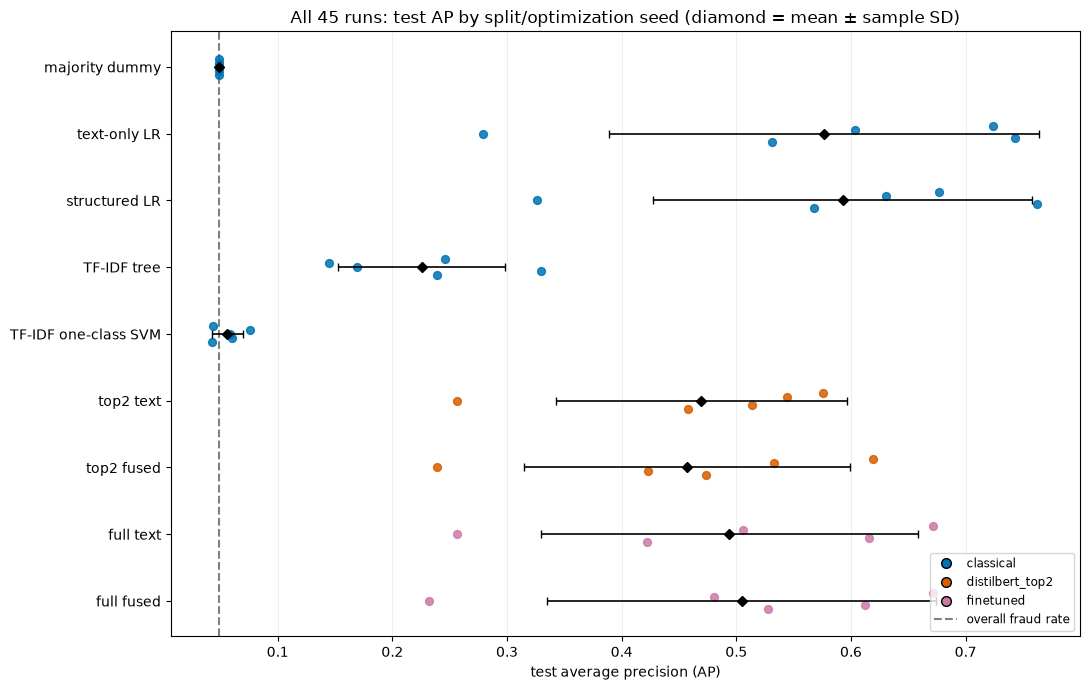

In [9]:
ARM_COLORS = {
    "classical": "#0072B2",
    "distilbert_top2": "#D55E00",
    "finetuned": "#CC79A7",
}
fig, ax = plt.subplots(figsize=(11, 7))
for position, model in enumerate(MODEL_ORDER):
    model_runs = res[res["model"] == model].sort_values("seed")
    values = model_runs["test_pr_auc"].to_numpy()
    color = ARM_COLORS[MODEL_ARM[model]]
    ax.scatter(values, np.full(5, position) + np.linspace(-0.12, 0.12, 5),
               color=color, s=32, alpha=0.85, zorder=3)
    ax.errorbar(values.mean(), position, xerr=values.std(ddof=1), fmt="D", ms=5,
                color="black", capsize=3, linewidth=1.2, zorder=4)
fraud_rate_line = ax.axvline(
    df["fraudulent"].mean(), color="grey", linestyle="--", label="overall fraud rate"
)
ax.set_yticks(range(len(MODEL_ORDER)), [MODEL_LABELS[model] for model in MODEL_ORDER])
ax.invert_yaxis()
ax.set_xlabel("test average precision (AP)")
ax.set_title("All 45 runs: test AP by split/optimization seed (diamond = mean ± sample SD)")
arm_handles = [Line2D([0], [0], marker="o", color="none", markerfacecolor=color,
                      label=arm, markersize=7) for arm, color in ARM_COLORS.items()]
ax.legend(handles=arm_handles + [fraud_rate_line], loc="lower right", fontsize="small")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()
plt.close(fig)

## 5. Selected seed-0 score diagnostics only

The six models below were chosen **by the comparison design, not by test score**: the two classical LR feature
variants and the text/fused variants of top2 and full tuning. These PR curves and confusion matrices are **seed-0
diagnostics only**, not summaries over seeds or evidence for selecting a model. The majority dummy is omitted from
PR curves because its constant score is uninformative; the complete tables still include it.

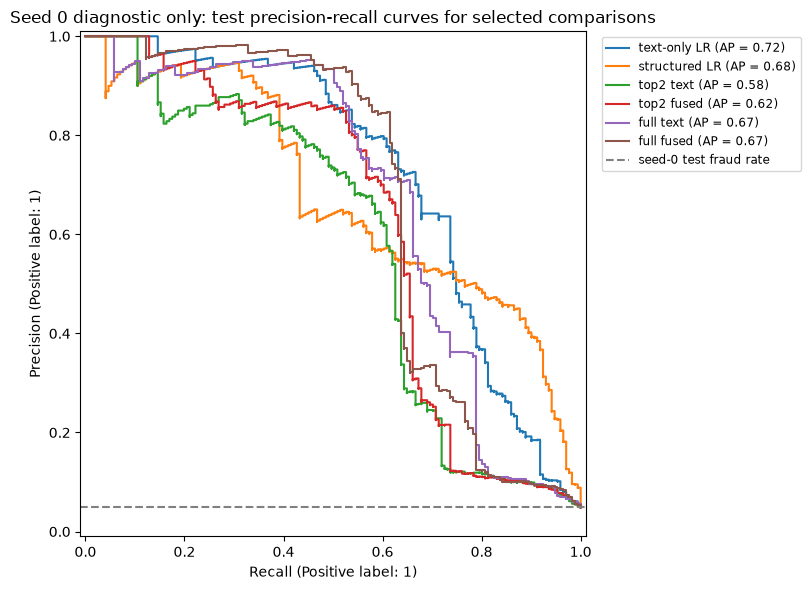

In [10]:
PRIMARY_DIAGNOSTIC = (
    "logreg_text", "logreg",
    "distilbert_top2_text", "distilbert_top2_fused",
    "distilbert_text", "distilbert_fused",
)
y_test_seed0 = df.iloc[split_cache[0]["test"]]["fraudulent"].to_numpy()
fig, ax = plt.subplots(figsize=(9, 6))
for model in PRIMARY_DIAGNOSTIC:
    scores = score_archive[(MODEL_ARM[model], model, 0)]
    assert np.array_equal(scores["y_test"], y_test_seed0)
    PrecisionRecallDisplay.from_predictions(
        y_test_seed0, scores["score_test"], name=MODEL_LABELS[model], ax=ax
    )
ax.axhline(y_test_seed0.mean(), color="grey", linestyle="--", label="seed-0 test fraud rate")
ax.set_title("Seed 0 diagnostic only: test precision-recall curves for selected comparisons")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize="small")
fig.tight_layout()
plt.show()
plt.close(fig)

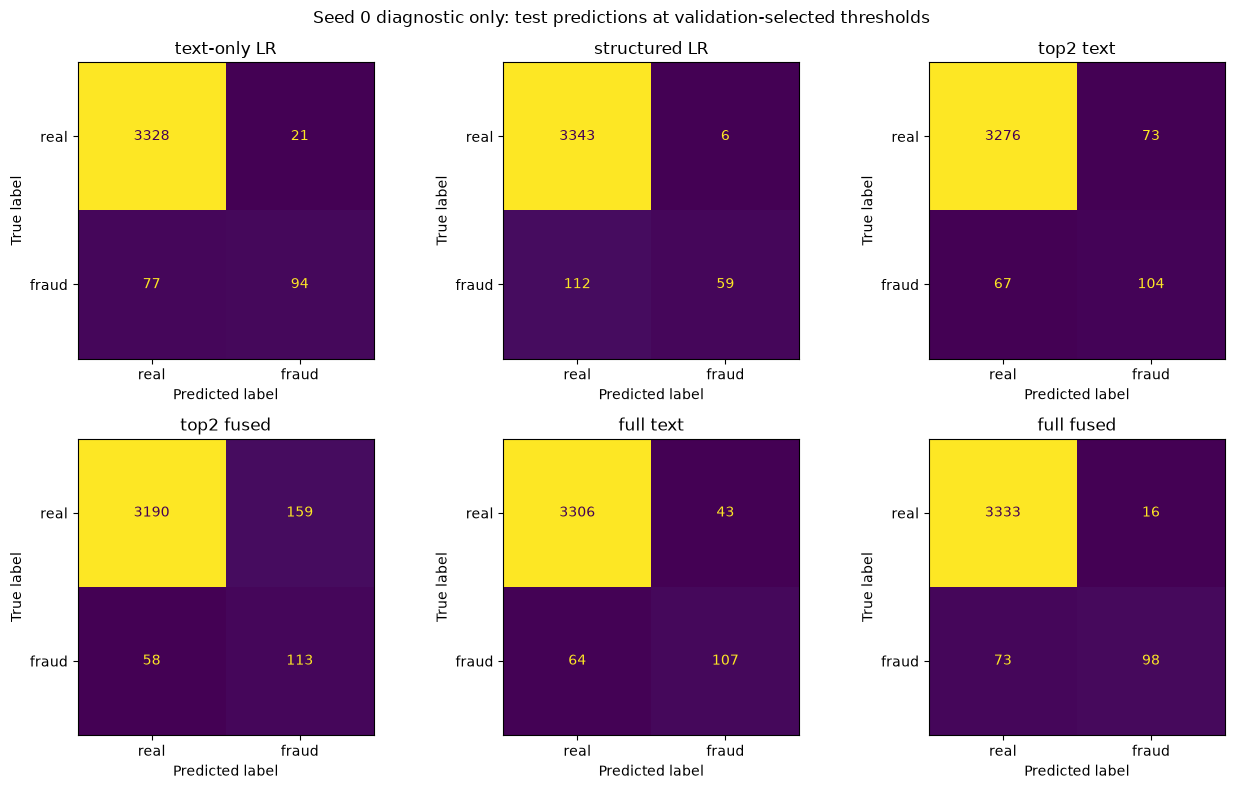

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, model in zip(axes.ravel(), PRIMARY_DIAGNOSTIC):
    scores = score_archive[(MODEL_ARM[model], model, 0)]
    threshold = float(records[(MODEL_ARM[model], model, 0)]["thr"])
    ConfusionMatrixDisplay.from_predictions(
        y_test_seed0, scores["score_test"] >= threshold,
        display_labels=["real", "fraud"], colorbar=False, ax=ax
    )
    ax.set_title(MODEL_LABELS[model])
fig.suptitle("Seed 0 diagnostic only: test predictions at validation-selected thresholds")
fig.tight_layout()
plt.show()
plt.close(fig)

## 6. Measured findings

The regression assertions below anchor the headline values to the loaded artifacts. They check observations, not a
preferred model. In particular, they encode the full-minus-top2 AP gains and the 5/5 structured-LR comparisons.

In [12]:
def model_mean(model: str, metric: str = "test_pr_auc") -> float:
    """Return one model's five-run mean for a saved metric."""
    return float(res.loc[res["model"] == model, metric].mean())


expected_four_decimal_means = {
    "distilbert_text": 0.4941,
    "distilbert_fused": 0.5047,
    "distilbert_top2_text": 0.4696,
    "distilbert_top2_fused": 0.4573,
}
for model, expected_mean in expected_four_decimal_means.items():
    assert round(model_mean(model), 4) == expected_mean
assert round(model_mean("logreg"), 3) == 0.593

test_ap = res.pivot(index="seed", columns="model", values="test_pr_auc")
for full_model in ("distilbert_text", "distilbert_fused"):
    assert int((test_ap["logreg"] > test_ap[full_model]).sum()) == 5
for comparison, rows in adaptation_deltas.groupby(level="comparison", sort=False):
    deltas = rows["test AP Δ"]
    if comparison == "full text − top2 text":
        assert round(float(deltas.mean()), 4) == 0.0245
        assert int((deltas > 0).sum()) == 2
    else:
        assert round(float(deltas.mean()), 4) == 0.0474
        assert int((deltas > 0).sum()) == 3

headline = res[res["model"].isin([
    "logreg", *EXPECTED_MODELS["distilbert_top2"], *EXPECTED_MODELS["finetuned"]
])].groupby("model")["test_pr_auc"].agg(["mean", "std"])
headline = headline.reindex([
    "logreg", *EXPECTED_MODELS["distilbert_top2"], *EXPECTED_MODELS["finetuned"]
])
print("Headline test AP, mean and sample SD:")
display(headline.round(6))
print("Structured LR has higher test AP than full text and full fused in 5/5 splits for each comparison.")
print(f"Structured LR mean test AP: {model_mean('logreg'):.4f} "
      f"({model_mean('logreg'):.3f} to three decimals).")
for comparison, rows in adaptation_deltas.groupby(level="comparison", sort=False):
    deltas = rows["test AP Δ"]
    print(f"{comparison}: mean test AP Δ {deltas.mean():+.4f}, "
          f"sample SD {deltas.std(ddof=1):.4f}, positive {int((deltas > 0).sum())}/5.")
for comparison, rows in fusion_deltas.groupby(level="comparison", sort=False):
    deltas = rows["test AP Δ"]
    print(f"{comparison}: mean test AP Δ {deltas.mean():+.4f}, "
          f"sample SD {deltas.std(ddof=1):.4f}, positive {int((deltas > 0).sum())}/5.")

Headline test AP, mean and sample SD:


,mean,std
model,,
logreg,0.592756,0.165095
distilbert_top2_text,0.469598,0.126980
distilbert_top2_fused,0.457273,0.142187
distilbert_text,0.494051,0.164466
distilbert_fused,0.504694,0.169610


Structured LR has higher test AP than full text and full fused in 5/5 splits for each comparison.
Structured LR mean test AP: 0.5928 (0.593 to three decimals).
full text − top2 text: mean test AP Δ +0.0245, sample SD 0.0696, positive 2/5.
full fused − top2 fused: mean test AP Δ +0.0474, sample SD 0.0910, positive 3/5.
top2 fused − top2 text: mean test AP Δ -0.0123, sample SD 0.0502, positive 2/5.
full fused − full text: mean test AP Δ +0.0106, sample SD 0.0543, positive 2/5.


### Interpretation constrained to the saved outputs

- **Scale of the fine-tuning results.** Mean test AP is 0.4941 for full text and 0.5047 for full fused;
  top2 text and top2 fused average 0.4696 and 0.4573. Their sample SDs, shown above, are substantial relative to
  mean differences, so these means do not establish stable ordering.
- **Structured LR comparison.** The current artifacts give structured LR a mean test AP of **0.593 ± 0.165**
  to three decimals. It is higher than full text
  in 5/5 splits and higher than full fused in 5/5 splits. The per-seed margins are small on seed 0 and larger on
  other splits; this remains an exploratory comparison, not a test-selected deployment decision.
- **Adaptation ablation.** Full-minus-top2 mean test AP is **+0.0245 ± 0.0696** for text with **2/5** positive
  splits, and **+0.0474 ± 0.0910** for fusion with **3/5** positive splits. The standard deviations exceed the
  respective means. Full tuning therefore has a positive average delta here, but not a consistent per-split win.
- **Fusion is inconsistent.** Top2 fusion has mean test AP delta **−0.0123 ± 0.0502** with 2/5 positive splits;
  full fusion has **+0.0106 ± 0.0543**, also with only 2/5 positive splits. Top2 fusion improves validation AP in
  5/5 splits yet has a negative mean test delta, an explicit validation/test reversal. Full fusion also changes
  sign between mean validation and mean test AP. No uniform structured-feature benefit is supported.
- **Threshold and operating-point caution.** Structured LR improves mean test AP over text-only classical LR but
  lowers mean test F1 in the paired summary. Threshold-free AP gains need not coincide with gains at a validation-
  F1 threshold. Several paired F1 deltas reverse from validation to test, and the large test-F1 SDs show unstable
  operating points. These observations support caution about threshold-overfit; they do not prove its cause.
- **Group concentration.** Seed 2 assigns 101 of 171 test fraud rows (59.1%) to one related-ad group and 139/171
  (81.3%) to five groups. It is also the minimum-test-AP split for all four top2/full runs. Other seed diagnostics
  and the 20.5% single-group share show why row-level variability alone is an incomplete description. This is a
  measured co-occurrence, **not evidence that group identity caused the low scores**.

## 7. Exploratory status, selection history, and timing limitations

1. **No untouched final evaluation.** Full-data EDA informed the design; seed-0 validation/test scores were
   previously inspected and are plotted again above. Model and analysis decisions therefore have a selection
   history. The five test splits are reused, overlapping views of the same 17,597 cleaned rows—not independent
   confirmations. There is no final untouched external test set.
2. **Split and optimization are confounded.** Each grouped split has one optimization seed. Same-seed pairing aligns
   rows but cannot separate data-split variability from optimizer stochasticity. Five runs provide descriptive mean/
   SD only, not a reliable population inference or optimizer replication study.
3. **Grouping controls identity leakage, not difficulty.** Group-disjoint validation/test boundaries prevent the
   same related-ad group from crossing splits, but entire concentrated clusters still move between splits. AP and
   threshold reversals must be read with this composition variation and the small fraud counts (171 per test split).
4. **Times are not controlled benchmarks.** Reported values are saved wall-clock run seconds from heterogeneous
   pipelines and hardware contexts. Tokenization, preprocessing, training, evaluation, and inference are not
   consistently isolated across arms, so the table cannot support a CPU-versus-GPU or end-to-end latency claim.